# Pandas

`pandas` is the go-to library for working with tabular data in Python. It is built on top of NumPy and gives us two core structures:

- `Series`: a one-dimensional labeled array (a single column).
- `DataFrame`: a two-dimensional table made of several `Series` that share the same index.

In [1]:
## numpy for numeric operations, pandas for tables, matplotlib for charts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
## check the installed pandas version
pd.__version__

'3.0.5'

## Series
A `Series` is like a list with an index attached to each value.

In [3]:
## a Series from a list gets a default integer index (0, 1, 2, ...)
serie = pd.Series([0.91, 0.87, 0.78, 0.95])
serie

0    0.91
1    0.87
2    0.78
3    0.95
dtype: float64

In [4]:
## custom labels for the index
accuracy = pd.Series([0.91, 0.87, 0.78, 0.95], index=['rf', 'svm', 'knn', 'xgb'], name='accuracy')
accuracy

rf     0.91
svm    0.87
knn    0.78
xgb    0.95
Name: accuracy, dtype: float64

In [5]:
## access a single value by its label
accuracy['xgb']

np.float64(0.95)

In [6]:
## operations are vectorized, so they apply to every element
accuracy * 100

rf     91.0
svm    87.0
knn    78.0
xgb    95.0
Name: accuracy, dtype: float64

In [7]:
## boolean filter: keep only the values above 0.85
accuracy[accuracy > 0.85]

rf     0.91
svm    0.87
xgb    0.95
Name: accuracy, dtype: float64

# Creating DataFrames
## From a Dictionary of Lists
Each key becomes a column name and each list becomes the column values. All lists must have the same length.

In [8]:
## each key becomes a column and each list its values
data = {
    'model': ['rf', 'svm', 'knn', 'xgb', 'logreg'],
    'accuracy': [0.91, 0.87, 0.78, 0.95, 0.84],
    'train_time_sec': [12.5, 30.1, 0.4, 18.7, 2.3]
}

df_models = pd.DataFrame(data)
df_models

,model,accuracy,train_time_sec
0,rf,0.91,12.5
1,svm,0.87,30.1
2,knn,0.78,0.4
3,xgb,0.95,18.7
4,logreg,0.84,2.3


## From a List of Dictionaries
Useful when each record arrives as a dictionary, for example rows coming from a JSON API. Missing keys become `NaN`.

In [9]:
## each dictionary becomes a row; missing keys become NaN
records = [
    {'name': 'Ana', 'age': 28, 'city': 'Lima'},
    {'name': 'Luis', 'age': 35, 'city': 'Bogotá'},
    {'name': 'Sofía', 'city': 'Quito'},
]

df_persons = pd.DataFrame(records)
df_persons

,name,age,city
0,Ana,28.0,Lima
1,Luis,35.0,Bogotá
2,Sofía,NaN,Quito


## Anatomy of a DataFrame
Every DataFrame has an index (row labels), columns, and a data type per column.

In [10]:
## number of (rows, columns)
df_models.shape

(5, 3)

In [11]:
## column names
df_models.columns

Index(['model', 'accuracy', 'train_time_sec'], dtype='str')

In [12]:
## row labels
df_models.index

RangeIndex(start=0, stop=5, step=1)

In [13]:
## data type of each column
df_models.dtypes

model                 str
accuracy          float64
train_time_sec    float64
dtype: object

# Reading CSV Files
`pd.read_csv()` loads a CSV file into a DataFrame. We'll use the Palmer Penguins dataset: measurements of three penguin species from three islands in Antarctica.

In [14]:
## read csv
df_penguins = pd.read_csv('../data/penguins.csv')
df_penguins

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,4,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,5,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...,...
339,340,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,341,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,342,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,343,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


## First Look at the Data
These are the first methods to run whenever you load a new dataset.

In [15]:
## first 5 rows
df_penguins.head()

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,4,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,5,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [16]:
## last n rows
df_penguins.tail()

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,340,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,341,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,342,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,343,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,344,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [17]:
## random rows, random_state makes the sample reproducible
df_penguins.sample(5, random_state=42)

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
194,195,Gentoo,Biscoe,45.3,13.7,210.0,4300.0,female,2008
157,158,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,female,2007
225,226,Gentoo,Biscoe,46.5,14.8,217.0,5200.0,female,2008
208,209,Gentoo,Biscoe,43.8,13.9,208.0,4300.0,female,2008
318,319,Chinstrap,Dream,50.9,19.1,196.0,3550.0,male,2008


In [18]:
## number of (rows, columns)
df_penguins.shape

(344, 9)

In [19]:
## column types and non-null counts
df_penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              344 non-null    int64  
 1   species            344 non-null    str    
 2   island             344 non-null    str    
 3   bill_length_mm     342 non-null    float64
 4   bill_depth_mm      342 non-null    float64
 5   flipper_length_mm  342 non-null    float64
 6   body_mass_g        342 non-null    float64
 7   sex                333 non-null    str    
 8   year               344 non-null    int64  
dtypes: float64(4), int64(2), str(3)
memory usage: 24.3 KB


In [20]:
## summary statistics of the numeric columns
df_penguins.describe()

,rowid,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,344.000000,342.000000,342.000000,342.000000,342.000000,344.000000
mean,172.500000,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,99.448479,5.459584,1.974793,14.061714,801.954536,0.818356
min,1.000000,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,86.750000,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,172.500000,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,258.250000,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,344.000000,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [21]:
## summary of the text columns
df_penguins.describe(include=['str'])

,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


# Selecting Data
## Columns
A single column returns a `Series`, a list of columns returns a `DataFrame`.

In [22]:
## a single column returns a Series
df_penguins['species']

0         Adelie
1         Adelie
2         Adelie
3         Adelie
4         Adelie
         ...    
339    Chinstrap
340    Chinstrap
341    Chinstrap
342    Chinstrap
343    Chinstrap
Name: species, Length: 344, dtype: str

In [23]:
## a list of columns returns a DataFrame
df_penguins[['species', 'island', 'body_mass_g']]

,species,island,body_mass_g
0,Adelie,Torgersen,3750.0
1,Adelie,Torgersen,3800.0
2,Adelie,Torgersen,3250.0
3,Adelie,Torgersen,NaN
4,Adelie,Torgersen,3450.0
...,...,...,...
339,Chinstrap,Dream,4000.0
340,Chinstrap,Dream,3400.0
341,Chinstrap,Dream,3775.0
342,Chinstrap,Dream,4100.0


In [24]:
## unique values of a categorical column
df_penguins['species'].unique()

<StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

In [25]:
## how many rows there are for each value
df_penguins['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [26]:
## how many rows there are for each value (%)
df_penguins['species'].value_counts(normalize=True).round(4) * 100

species
Adelie       44.19
Gentoo       36.05
Chinstrap    19.77
Name: proportion, dtype: float64

## Rows with `loc` and `iloc`
- `loc` selects by **label** (index values and column names).
- `iloc` selects by **position** (integers, like a list).

In [27]:
## a single row by its index label
df_penguins.loc[0]

rowid                        1
species                 Adelie
island               Torgersen
bill_length_mm            39.1
bill_depth_mm             18.7
flipper_length_mm        181.0
body_mass_g             3750.0
sex                       male
year                      2007
Name: 0, dtype: object

In [28]:
## label ranges in loc include both ends
df_penguins.loc[0:5, ['species', 'bill_length_mm']]

,species,bill_length_mm
0,Adelie,39.1
1,Adelie,39.5
2,Adelie,40.3
3,Adelie,NaN
4,Adelie,36.7
5,Adelie,39.3


In [29]:
## position ranges in iloc exclude the end, like Python slices
df_penguins.iloc[0:5, 0:3]

,rowid,species,island
0,1,Adelie,Torgersen
1,2,Adelie,Torgersen
2,3,Adelie,Torgersen
3,4,Adelie,Torgersen
4,5,Adelie,Torgersen


## Boolean Filtering
A condition over a column returns a boolean `Series` that can be used as a mask. Combine conditions with `&` (and), `|` (or) and `~` (not), wrapping each one in parentheses.

In [30]:
## the condition returns True / False for each row
mask = df_penguins['body_mass_g'] > 5000
mask

0      False
1      False
2      False
3      False
4      False
       ...  
339    False
340    False
341    False
342    False
343    False
Name: body_mass_g, Length: 344, dtype: bool

In [31]:
## use the mask to keep only the True rows
df_penguins[mask]

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
153,154,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,male,2007
155,156,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,male,2007
156,157,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,male,2007
159,160,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,male,2007
161,162,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,male,2007
...,...,...,...,...,...,...,...,...,...
267,268,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,male,2009
269,270,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,male,2009
273,274,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,male,2009
274,275,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,female,2009


In [32]:
## heavy gentoo penguins
df_penguins[(df_penguins['species'] == 'Gentoo') & (df_penguins['body_mass_g'] > 5800)]

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
165,166,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,male,2007
167,168,Gentoo,Biscoe,49.3,15.7,217.0,5850.0,male,2007
169,170,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,male,2007
185,186,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,male,2007
229,230,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,male,2008
231,232,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,male,2008
263,264,Gentoo,Biscoe,49.8,15.9,229.0,5950.0,male,2009
267,268,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,male,2009
269,270,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,male,2009


In [33]:
## query lets you write the same filter as a string
df_penguins.query("species == 'Gentoo' and body_mass_g > 5800")

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
165,166,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,male,2007
167,168,Gentoo,Biscoe,49.3,15.7,217.0,5850.0,male,2007
169,170,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,male,2007
185,186,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,male,2007
229,230,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,male,2008
231,232,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,male,2008
263,264,Gentoo,Biscoe,49.8,15.9,229.0,5950.0,male,2009
267,268,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,male,2009
269,270,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,male,2009


In [34]:
## isin checks membership against a list
df_penguins[df_penguins['island'].isin(['Dream', 'Torgersen'])]

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,4,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,5,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...,...
339,340,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,341,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,342,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,343,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


In [35]:
## exclude rows where species is Adelie
df_penguins[~(df_penguins['species'] == 'Adelie')]

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
152,153,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,female,2007
153,154,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,male,2007
154,155,Gentoo,Biscoe,48.7,14.1,210.0,4450.0,female,2007
155,156,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,male,2007
156,157,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,male,2007
...,...,...,...,...,...,...,...,...,...
339,340,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,341,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,342,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,343,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


# Processing Data
## Missing Values
Real datasets have gaps. Pandas represents them as `NaN` and offers methods to find, drop, or fill them.

In [36]:
## count missing values per column
df_penguins.isna().sum()

rowid                 0
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [37]:
## rows with at least one missing value
df_penguins[df_penguins.isna().any(axis=1)]

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,4,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,9,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,10,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,11,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,12,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,48,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,179,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,219,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,257,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,269,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


In [38]:
## show the shape of data
print(df_penguins.shape)

## drop rows where every measurement is missing
measures = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df_clean = df_penguins.dropna(subset=measures, how='all')
df_clean.shape

(344, 9)


(342, 9)

In [39]:
## fill the remaining missing sex values with a placeholder
df_clean = df_clean.fillna({'sex': 'unknown'})
df_clean['sex'].value_counts()

sex
male       168
female     165
unknown      9
Name: count, dtype: int64

In [40]:
## verify that no missing values remain
df_clean.isna().sum()

rowid                0
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64

## Duplicates
`duplicated()` flags repeated rows and `drop_duplicates()` removes them.

In [41]:
## count fully repeated rows
df_clean.duplicated().sum()

np.int64(0)

In [42]:
## build a copy with duplicated rows to see it in action
df_dup = pd.concat([df_clean.head(3), df_clean.head(3)]).reset_index(drop=True)
df_dup

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
4,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
5,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007


In [43]:
## keep only the first occurrence of each row
df_dup.drop_duplicates(keep='first')

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007


## Renaming, Dropping, and Changing Types
Most methods return a **new** DataFrame instead of modifying the original, so we reassign the result.

In [44]:
## rename takes a dictionary {old_name: new_name}
df_clean = df_clean.rename(columns={'flipper_length_mm': 'flipper_mm', 'body_mass_g': 'mass_g'})
df_clean.columns

Index(['rowid', 'species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_mm', 'mass_g', 'sex', 'year'],
      dtype='str')

In [45]:
## drop a column we don't need
df_clean = df_clean.drop(columns=['rowid'])
df_clean.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


In [46]:
## the category type saves memory for repeated text values
df_clean['species'] = df_clean['species'].astype('category')
df_clean.dtypes

species           category
island                 str
bill_length_mm     float64
bill_depth_mm      float64
flipper_mm         float64
mass_g             float64
sex                    str
year                 int64
dtype: object

In [47]:
## display the integer codes assigned to each category
df_clean['species'].cat.codes

0      0
1      0
2      0
4      0
5      0
      ..
339    1
340    1
341    1
342    1
343    1
Length: 342, dtype: int8

In [48]:
## display the category labels
df_clean['species']

0         Adelie
1         Adelie
2         Adelie
4         Adelie
5         Adelie
         ...    
339    Chinstrap
340    Chinstrap
341    Chinstrap
342    Chinstrap
343    Chinstrap
Name: species, Length: 342, dtype: category
Categories (3, str): ['Adelie', 'Chinstrap', 'Gentoo']

## Sorting
`sort_values()` orders rows by one or more columns.

In [49]:
## heaviest penguins first
df_clean.sort_values('mass_g', ascending=False)

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year
169,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,male,2007
185,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,male,2007
269,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,male,2009
229,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,male,2008
231,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,male,2008
...,...,...,...,...,...,...,...,...
54,Adelie,Biscoe,34.5,18.1,187.0,2900.0,female,2008
298,Chinstrap,Dream,43.2,16.6,187.0,2900.0,female,2007
58,Adelie,Biscoe,36.5,16.6,181.0,2850.0,female,2008
64,Adelie,Biscoe,36.4,17.1,184.0,2850.0,female,2008


In [50]:
## sort by species, then by mass within each species
df_clean.sort_values(['species', 'mass_g'], ascending=[False, True])

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year
192,Gentoo,Biscoe,42.7,13.7,208.0,3950.0,female,2008
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,unknown,2007
168,Gentoo,Biscoe,42.0,13.5,210.0,4150.0,female,2007
166,Gentoo,Biscoe,45.8,14.6,210.0,4200.0,female,2007
198,Gentoo,Biscoe,45.5,13.9,210.0,4200.0,female,2008
...,...,...,...,...,...,...,...,...
39,Adelie,Dream,39.8,19.1,184.0,4650.0,male,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007
81,Adelie,Torgersen,42.9,17.6,196.0,4700.0,male,2008
101,Adelie,Biscoe,41.0,20.0,203.0,4725.0,male,2009


In [51]:
## shortcut for the top n rows of a column
df_clean.nlargest(10, 'bill_length_mm')

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year
185,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,male,2007
293,Chinstrap,Dream,58.0,17.8,181.0,3700.0,female,2007
253,Gentoo,Biscoe,55.9,17.0,228.0,5600.0,male,2009
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
267,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,male,2009
215,Gentoo,Biscoe,54.3,15.7,231.0,5650.0,male,2008
307,Chinstrap,Dream,54.2,20.8,201.0,4300.0,male,2008
315,Chinstrap,Dream,53.5,19.9,205.0,4500.0,male,2008
259,Gentoo,Biscoe,53.4,15.8,219.0,5500.0,male,2009
305,Chinstrap,Dream,52.8,20.0,205.0,4550.0,male,2008


# Transforming Data
## New Columns
Arithmetic between columns is vectorized, so there's no need for a loop.

In [52]:
## new columns computed from existing ones
df_clean['mass_kg'] = df_clean['mass_g'] / 1000
df_clean['bill_ratio'] = df_clean['bill_length_mm'] / df_clean['bill_depth_mm']
df_clean[['mass_g', 'mass_kg', 'bill_length_mm', 'bill_depth_mm', 'bill_ratio']]

,mass_g,mass_kg,bill_length_mm,bill_depth_mm,bill_ratio
0,3750.0,3.750,39.1,18.7,2.090909
1,3800.0,3.800,39.5,17.4,2.270115
2,3250.0,3.250,40.3,18.0,2.238889
4,3450.0,3.450,36.7,19.3,1.901554
5,3650.0,3.650,39.3,20.6,1.907767
...,...,...,...,...,...
339,4000.0,4.000,55.8,19.8,2.818182
340,3400.0,3.400,43.5,18.1,2.403315
341,3775.0,3.775,49.6,18.2,2.725275
342,4100.0,4.100,50.8,19.0,2.673684


In [53]:
## np.where works like a vectorized if / else
df_clean['is_heavy'] = np.where(df_clean['mass_kg'] > 4.5, 'heavy', 'light')
df_clean[['mass_kg', 'is_heavy']]

,mass_kg,is_heavy
0,3.750,light
1,3.800,light
2,3.250,light
4,3.450,light
5,3.650,light
...,...,...
339,4.000,light
340,3.400,light
341,3.775,light
342,4.100,light


## `map` and `apply`
- `map` replaces each value of a `Series` using a dictionary or a function.
- `apply` runs a function over each value, or over each row with `axis=1`.

In [54]:
## map a dictionary onto a column
island_codes = {
    'Biscoe': 'BIS',
    'Dream': 'DRE',
    'Torgersen': 'TOR'
}

## create a new column based on island
df_clean['island_code'] = df_clean['island'].map(island_codes)
df_clean[['island', 'island_code']]

,island,island_code
0,Torgersen,TOR
1,Torgersen,TOR
2,Torgersen,TOR
4,Torgersen,TOR
5,Torgersen,TOR
...,...,...
339,Dream,DRE
340,Dream,DRE
341,Dream,DRE
342,Dream,DRE


In [55]:
## a regular function applied to every value of the column
def bill_size_label(length):
    if length < 40:
        return 'short'

    elif length < 50:
        return 'medium'
        
    return 'long'

## create a new column based on bill length
df_clean['bill_size'] = df_clean['bill_length_mm'].apply(bill_size_label)
df_clean[['bill_length_mm', 'bill_size']]

,bill_length_mm,bill_size
0,39.1,short
1,39.5,short
2,40.3,medium
4,36.7,short
5,39.3,short
...,...,...
339,55.8,long
340,43.5,medium
341,49.6,medium
342,50.8,long


In [56]:
## apply over rows: each row arrives as a Series
df_clean['species_island'] = df_clean.apply(lambda row: f"{row['species']} from {row['island']}", axis=1)
df_clean[['species', 'island', 'species_island']]

,species,island,species_island
0,Adelie,Torgersen,Adelie from Torgersen
1,Adelie,Torgersen,Adelie from Torgersen
2,Adelie,Torgersen,Adelie from Torgersen
4,Adelie,Torgersen,Adelie from Torgersen
5,Adelie,Torgersen,Adelie from Torgersen
...,...,...,...
339,Chinstrap,Dream,Chinstrap from Dream
340,Chinstrap,Dream,Chinstrap from Dream
341,Chinstrap,Dream,Chinstrap from Dream
342,Chinstrap,Dream,Chinstrap from Dream


## Binning with `pd.cut`
`pd.cut()` turns a numeric column into categories using intervals, a common step in feature engineering.

In [57]:
## assign each flipper length to an interval: (170, 190], (190, 210], (210, 240]
df_clean['flipper_size'] = pd.cut(
    df_clean['flipper_mm'],
    bins=[170, 190, 210, 240],
    labels=['short', 'medium', 'long'],
)

## count penguins in each category
df_clean['flipper_size'].value_counts(dropna=False)

flipper_size
medium    143
long      100
short      99
Name: count, dtype: int64

## String Methods
The `.str` accessor applies string methods to a whole text column.

In [58]:
## convert every value to uppercase
df_clean['island'].str.upper()

0      TORGERSEN
1      TORGERSEN
2      TORGERSEN
4      TORGERSEN
5      TORGERSEN
         ...    
339        DREAM
340        DREAM
341        DREAM
342        DREAM
343        DREAM
Name: island, Length: 342, dtype: str

In [59]:
## filter islands whose name starts with T
df_clean[df_clean['island'].str.startswith('T')].head()

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year,mass_kg,bill_ratio,is_heavy,island_code,bill_size,species_island,flipper_size
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75,2.090909,light,TOR,short,Adelie from Torgersen,short
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80,2.270115,light,TOR,short,Adelie from Torgersen,short
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25,2.238889,light,TOR,medium,Adelie from Torgersen,medium
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.45,1.901554,light,TOR,short,Adelie from Torgersen,medium
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007,3.65,1.907767,light,TOR,short,Adelie from Torgersen,short


## Grouping and Aggregating
`groupby()` follows the *split-apply-combine* pattern: split the rows into groups, apply a function to each group, and combine the results.

In [60]:
## mean body mass per species
df_clean.groupby('species', observed=True)['mass_g'].mean()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: mass_g, dtype: float64

In [61]:
## several aggregations at once
df_clean.groupby('species', observed=True)['mass_g'].agg(['count', 'mean', 'min', 'max', 'count'])

,count,mean,min,max,count
species,,,,,
Adelie,151,3700.662252,2850.0,4775.0,151
Chinstrap,68,3733.088235,2700.0,4800.0,68
Gentoo,123,5076.016260,3950.0,6300.0,123


In [62]:
## named aggregations give clean column names
summary = df_clean.groupby(['species'], observed=True).agg(
    n=('mass_g', 'count'),    
    mean_mass=('mass_g', 'mean'),
    min_mass=('mass_g', 'min'),
    max_mass=('mass_g', 'max'),    
)

summary

,n,mean_mass,min_mass,max_mass
species,,,,
Adelie,151,3700.662252,2850.0,4775.0
Chinstrap,68,3733.088235,2700.0,4800.0
Gentoo,123,5076.016260,3950.0,6300.0


In [63]:
## reset_index turns the group keys back into columns
summary.reset_index()

,species,n,mean_mass,min_mass,max_mass
0,Adelie,151,3700.662252,2850.0,4775.0
1,Chinstrap,68,3733.088235,2700.0,4800.0
2,Gentoo,123,5076.016260,3950.0,6300.0


## Pivot Tables and Crosstabs
Reshape the data into a table with one variable in rows and another in columns.

In [64]:
## rows = species, columns = islands, cells = mean body mass
df_clean.pivot_table(
    index='species',
    columns='island',
    values='mass_g',
    aggfunc='mean',
    observed=True
).round(2)

island,Biscoe,Dream,Torgersen
species,,,
Adelie,3709.66,3688.39,3706.37
Chinstrap,NaN,3733.09,NaN
Gentoo,5076.02,NaN,NaN


In [65]:
## counts of each combination
pd.crosstab(df_clean['species'], df_clean['island'])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,51
Chinstrap,0,68,0
Gentoo,123,0,0


## Combining DataFrames
- `pd.concat()` stacks DataFrames one after another.
- `pd.merge()` joins two DataFrames on a shared key, like a SQL `JOIN`.

In [66]:
## a small table with extra information about each island
islands = pd.DataFrame({
    'island': ['Biscoe', 'Dream', 'Torgersen'],
    'area_km2': [1.9, 0.6, 0.1],
})

islands

,island,area_km2
0,Biscoe,1.9
1,Dream,0.6
2,Torgersen,0.1


In [67]:
## left join: keep every penguin and add its island's area
df_merged = pd.merge(
    df_clean,
    islands,
    on='island',
    how='left'
)

df_merged

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year,mass_kg,bill_ratio,is_heavy,island_code,bill_size,species_island,flipper_size,area_km2
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.750,2.090909,light,TOR,short,Adelie from Torgersen,short,0.1
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.800,2.270115,light,TOR,short,Adelie from Torgersen,short,0.1
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.250,2.238889,light,TOR,medium,Adelie from Torgersen,medium,0.1
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.450,1.901554,light,TOR,short,Adelie from Torgersen,medium,0.1
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007,3.650,1.907767,light,TOR,short,Adelie from Torgersen,short,0.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009,4.000,2.818182,light,DRE,long,Chinstrap from Dream,medium,0.6
338,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009,3.400,2.403315,light,DRE,medium,Chinstrap from Dream,medium,0.6
339,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009,3.775,2.725275,light,DRE,medium,Chinstrap from Dream,medium,0.6
340,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009,4.100,2.673684,light,DRE,long,Chinstrap from Dream,medium,0.6


In [68]:
## stack two filtered tables vertically
adelie = df_merged[df_merged['species'] == 'Adelie'].head(3)
gentoo = df_merged[df_merged['species'] == 'Gentoo'].head(3)
chinstrap = df_merged[df_merged['species'] == 'Chinstrap'].head(3)

## concatenate the filtered DataFrames vertically
df_combined = pd.concat([adelie, gentoo, chinstrap])
df_combined

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year,mass_kg,bill_ratio,is_heavy,island_code,bill_size,species_island,flipper_size,area_km2
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75,2.090909,light,TOR,short,Adelie from Torgersen,short,0.1
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80,2.270115,light,TOR,short,Adelie from Torgersen,short,0.1
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25,2.238889,light,TOR,medium,Adelie from Torgersen,medium,0.1
151,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,female,2007,4.50,3.492424,light,BIS,medium,Gentoo from Biscoe,long,1.9
152,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,male,2007,5.70,3.067485,heavy,BIS,long,Gentoo from Biscoe,long,1.9
153,Gentoo,Biscoe,48.7,14.1,210.0,4450.0,female,2007,4.45,3.453901,light,BIS,medium,Gentoo from Biscoe,medium,1.9
274,Chinstrap,Dream,46.5,17.9,192.0,3500.0,female,2007,3.50,2.597765,light,DRE,medium,Chinstrap from Dream,medium,0.6
275,Chinstrap,Dream,50.0,19.5,196.0,3900.0,male,2007,3.90,2.564103,light,DRE,long,Chinstrap from Dream,medium,0.6
276,Chinstrap,Dream,51.3,19.2,193.0,3650.0,male,2007,3.65,2.671875,light,DRE,long,Chinstrap from Dream,medium,0.6


In [69]:
## reset the index to create a continuous sequence
df_combined = df_combined.reset_index(drop=True)
df_combined

,species,island,bill_length_mm,bill_depth_mm,flipper_mm,mass_g,sex,year,mass_kg,bill_ratio,is_heavy,island_code,bill_size,species_island,flipper_size,area_km2
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75,2.090909,light,TOR,short,Adelie from Torgersen,short,0.1
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80,2.270115,light,TOR,short,Adelie from Torgersen,short,0.1
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25,2.238889,light,TOR,medium,Adelie from Torgersen,medium,0.1
3,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,female,2007,4.50,3.492424,light,BIS,medium,Gentoo from Biscoe,long,1.9
4,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,male,2007,5.70,3.067485,heavy,BIS,long,Gentoo from Biscoe,long,1.9
5,Gentoo,Biscoe,48.7,14.1,210.0,4450.0,female,2007,4.45,3.453901,light,BIS,medium,Gentoo from Biscoe,medium,1.9
6,Chinstrap,Dream,46.5,17.9,192.0,3500.0,female,2007,3.50,2.597765,light,DRE,medium,Chinstrap from Dream,medium,0.6
7,Chinstrap,Dream,50.0,19.5,196.0,3900.0,male,2007,3.90,2.564103,light,DRE,long,Chinstrap from Dream,medium,0.6
8,Chinstrap,Dream,51.3,19.2,193.0,3650.0,male,2007,3.65,2.671875,light,DRE,long,Chinstrap from Dream,medium,0.6


# Visualizations
DataFrames and Series have a `.plot()` method that draws charts with matplotlib, so a quick exploratory plot is one line away.

## Histogram
Shows the distribution of a numeric variable.

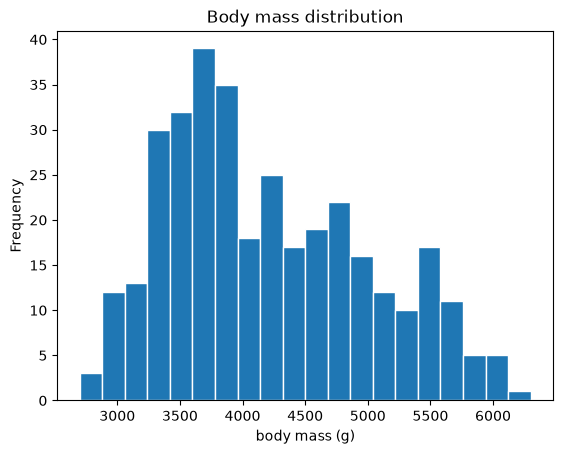

In [70]:
## distribution of body mass in 20 bins
df_clean['mass_g'].plot(kind='hist', bins=20, edgecolor='white', title='Body mass distribution')

plt.xlabel('body mass (g)')
plt.show()

## Bar Chart
Ideal to compare a value across categories, usually after a `groupby` or `value_counts`.

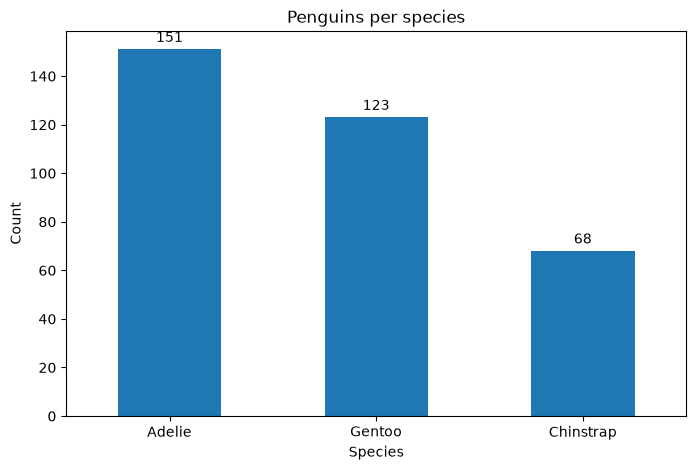

In [71]:
## plot the number of penguins per species
ax = df_clean['species'].value_counts().plot.bar(
    figsize=(8, 5),
    title='Penguins per species',
    rot=0,
)

## add value labels above each bar
ax.bar_label(ax.containers[0], padding=3)

## customize the axes
ax.set(xlabel='Species', ylabel='Count')

plt.show()

## Scatter Plot
Shows the relationship between two numeric variables. Coloring by species reveals the clusters.

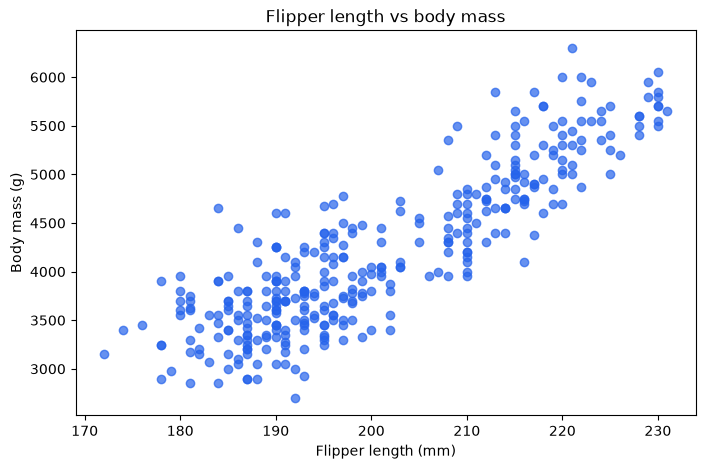

In [72]:
## plot flipper length vs body mass
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df_clean['flipper_mm'],
    df_clean['mass_g'],
    alpha=0.7,
    color='#2563EB',
)

## customize the plot
ax.set(
    title='Flipper length vs body mass',
    xlabel='Flipper length (mm)',
    ylabel='Body mass (g)',
)

plt.show()

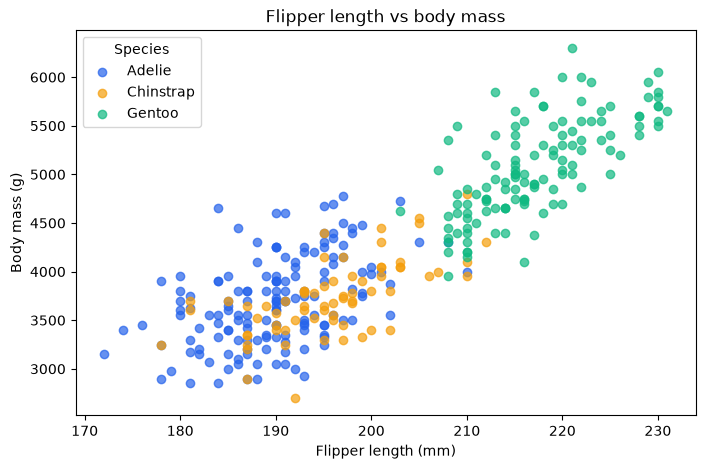

In [73]:
## define colors for each penguin species
species_colors = {
    'Adelie': '#2563EB',
    'Chinstrap': '#F59E0B',
    'Gentoo': '#10B981',
}

## plot flipper length vs body mass by species
fig, ax = plt.subplots(figsize=(8, 5))

for species, group in df_clean.groupby('species', observed=True):
    ax.scatter(
        group['flipper_mm'],
        group['mass_g'],
        label=species,
        color=species_colors[species],
        alpha=0.7,
    )

## customize the plot
ax.set(
    title='Flipper length vs body mass',
    xlabel='Flipper length (mm)',
    ylabel='Body mass (g)',
)

ax.legend(title='Species')
plt.show()

## Box Plot
Summarizes a distribution per group: median, quartiles, and outliers.

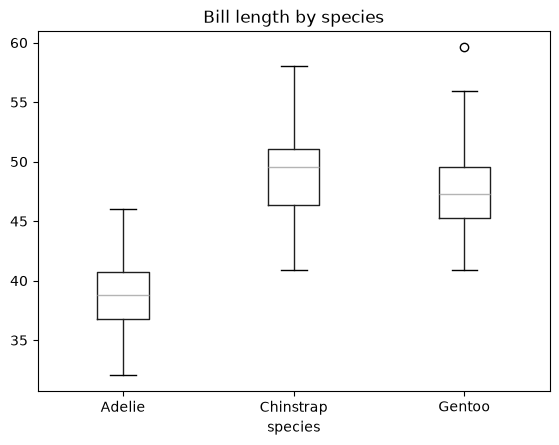

In [74]:
## one box per species; suptitle removes the automatic pandas title
df_clean.boxplot(column='bill_length_mm', by='species', grid=False)

plt.suptitle('')
plt.title('Bill length by species')
plt.show()

# Saving Data
`to_csv()` writes a DataFrame back to disk. Use `index=False` if the index carries no information.

In [75]:
## save the cleaned dataset
df_clean.to_csv('../data/penguins_clean.csv', index=False)

In [76]:
## remove the file to keep the repo clean
import os
os.remove('../data/penguins_clean.csv')